In [12]:
from nes.dists import XDiagNormal
import numpy as np
from matplotlib import pyplot as plt

In [13]:
dist = XDiagNormal.from_dimensions(1)
dist.set_init_params(np.array([20, 1], dtype=np.float64))

In [14]:
samples = np.array(
    [
        [1],
        [0],
        [-1],
    ], dtype=np.float64
) + 5
fitness = np.array(
    [
        [1],
        [0],
        [1],
    ], dtype=np.float64
)

In [15]:
for _ in range(10):
    print(dist._params, dist._gradient(samples, fitness), dist._inverse_fisher(samples))
    dist._params += dist._gradient(samples, fitness) * dist._inverse_fisher(samples)

[20.  0.] [-15. 225.] [1. 2.]
[  5. 450.] [ 0. -1.] [inf  2.]
[ nan 448.] [nan nan] [inf  2.]
[nan nan] [nan nan] [nan  2.]
[nan nan] [nan nan] [nan  2.]
[nan nan] [nan nan] [nan  2.]
[nan nan] [nan nan] [nan  2.]
[nan nan] [nan nan] [nan  2.]
[nan nan] [nan nan] [nan  2.]
[nan nan] [nan nan] [nan  2.]


/home/christof/nes/nes/dists/xdiag_normal.py:52: RuntimeWarning: overflow encountered in exp
  return np.exp(2 * self._params[self._num_dimensions :])
/tmp/ipykernel_260635/1524131414.py:3: RuntimeWarning: invalid value encountered in multiply
  dist._params += dist._gradient(samples, fitness) * dist._inverse_fisher(samples)


[[18.         18.66666667 19.33333333 20.         20.66666667 21.33333333
  22.        ]] [[-324.         -348.44444444 -373.77777778 -400.         -427.11111111
  -455.11111111 -484.        ]]
[20.  0.] [-0.86486486  0.74894895] [1. 2.]
[[10.19057914 13.17209781 16.15361647 19.13513514 22.1166538  25.09817246
  28.07969113]] [[-103.84790322 -173.50416059 -260.93932507 -366.15339664 -489.14637531
  -629.91826108 -788.46905394]]
[19.13513514  1.4978979 ] [-0.17591378  0.65519353] [20.00127049  2.        ]
[[-17.54627597  -6.491972     4.56233197  15.61663594  26.67093991
   37.72524388  48.77954785]] [[ -307.87180026   -42.14570041   -20.81487302  -243.8793181
   -711.33903564 -1423.19402564 -2379.44428811]]
[15.61663594  2.80828496] [-0.03371793  0.38202186] [274.94468152   2.        ]
[[-64.85272059 -41.11978981 -17.38685902   6.34607177  30.07900256
   53.81193334  77.54486413]] [[-4205.87536825 -1690.83711362  -302.3028665    -40.27262691
   -904.74639483 -2895.72417027 -6013.205953

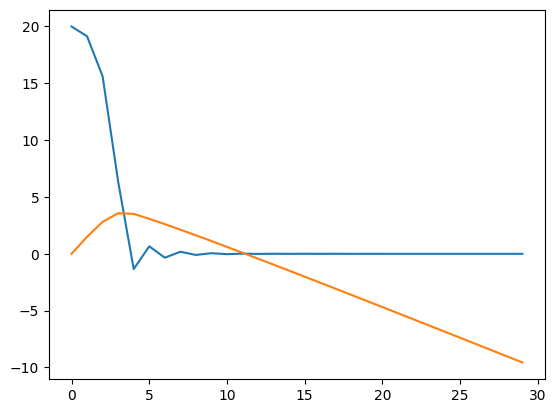

In [16]:
dist = XDiagNormal.from_dimensions(1)
dist.set_init_params(np.array([20, 1], dtype=np.float64))
params = []
n = 3
for _ in range(30):
    samples = np.arange(-n, n+1).reshape(-1, 1)*2/n*dist._variance**0.5+dist._mean
    fitness = -samples**2
    print(samples.T, fitness.T)
    print(dist._params, dist._gradient(samples, fitness), dist._inverse_fisher(samples))
    params.append(dist._params.copy())
    dist._params += dist._gradient(samples, fitness) * dist._inverse_fisher(samples)
params = np.array(params)
plt.plot(params[:, 0])
plt.plot(params[:, 1])

In [17]:
def get_samples(distr, number: int):
    """Generate samples."""
    z = np.random.randn(number, distr._num_dimensions)
    return distr._mean + z * np.sqrt(distr._variance)

[[20.05935644 20.40294856 18.19791917 19.67437227 19.87165195 19.690208
  18.82936463 19.9749816  20.64554785 19.60734499]] [[-402.37778062 -416.28030986 -331.16426216 -387.08092409 -394.88255132
  -387.704291   -354.54497254 -398.99989005 -426.23864585 -384.44797736]]
[20.  0.] [-0.78072637  0.11848162] [1. 2.]
[[18.96959185 17.3604702  16.82840477 17.76377944 19.30804698 15.85749533
  17.48861224 16.85745004 20.35587449 18.74410015]] [[-359.84541494 -301.38592543 -283.19520715 -315.55186001 -372.80067812
  -251.46015819 -305.85155812 -284.17362198 -414.36162643 -351.34129041]]
[19.21927363  0.23696323] [-1.20576955  1.93462665] [1.60628887 2.        ]
[[-31.87846288  -0.79470731 -24.92801641   5.56018241  -0.43636232
   25.43532447 -54.99889599  87.69631757 -64.14085501  52.47444197]] [[-1.01623640e+03 -6.31559715e-01 -6.21406002e+02 -3.09156284e+01
  -1.90412073e-01 -6.46955731e+02 -3.02487856e+03 -7.69064412e+03
  -4.11404928e+03 -2.75356706e+03]]
[17.28245943  4.10621654] [-0.0066

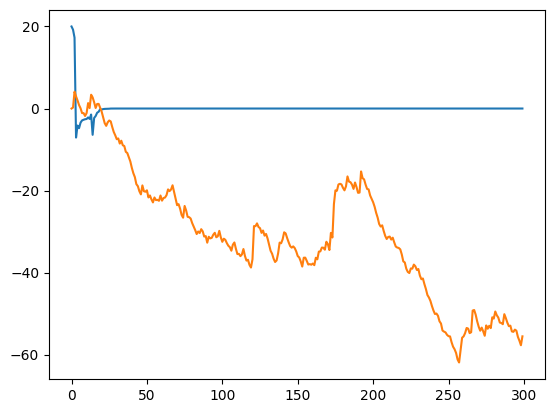

In [18]:
dist = XDiagNormal.from_dimensions(1)
dist.set_init_params(np.array([20, 1], dtype=np.float64))
params = []
n = 10
for _ in range(300):
    samples = get_samples(dist, n)
    fitness = -samples**2
    print(samples.T, fitness.T)
    print(dist._params, dist._gradient(samples, fitness), dist._inverse_fisher(samples))
    params.append(dist._params.copy())
    dist._params += dist._gradient(samples, fitness) * dist._inverse_fisher(samples)
params = np.array(params)
plt.plot(params[:, 0])
plt.plot(params[:, 1])

In [19]:
def simple_update(dist, namspace):
    dist._params += dist._gradient(namspace["samples"], namspace["fitness"]) * dist._inverse_fisher(namspace["samples"])

def try_convergence(dist, n, d, tolerance=1e-5, ufunc=simple_update):
    params = []
    emas = []
    ema = dist.parameters
    prev_params = dist.parameters
    for _ in range(1000):
        samples = dist.get_samples(n)
        fitness = (-samples**2).sum(axis=1).reshape(-1, 1)
        params.append(dist.parameters)
        ufunc(dist, locals())
        diff = dist.parameters - prev_params
        ema = ema + (diff - ema) * 0.1
        prev_params = dist.parameters
        emas.append(ema)
        if ema.sum() <= tolerance / d:
            break
    params = np.array(params)
    emas = np.array(emas)
    return params, emas

In [ ]:
def run_sample_benchmark(d, iters = 100, ns=np.logspace(0, 3, 32).astype(int)):
    avg_distances = []
    avg_steps = []
    viable_ns = []
    iparams = np.array([10] * d + [40] * d, dtype=np.float64)
    for n in ns:
        distance = 0
        steps = 0
        for _ in range(iters):
            dist = XDiagNormal.from_dimensions(d)
            dist.set_init_params(iparams.copy())
            params, _ = try_convergence(dist, n, d)
            # distance += (params[-1, :d]**2).sum()**0.5
            distance += (params[-1, :d]**2).sum()**0.5
            print(params[-1, :d]**2)
            steps += params.shape[0]
        avg_distances.append(distance/iters)
        avg_steps.append(steps/iters)
        viable_ns.append(n)
    return viable_ns, avg_steps, avg_distances

/home/christof/nes/nes/dists/xdiag_normal.py:68: RuntimeWarning: invalid value encountered in divide
  weighted_gradients = gradients * (adjusted_fitness / adjusted_fitness.sum())


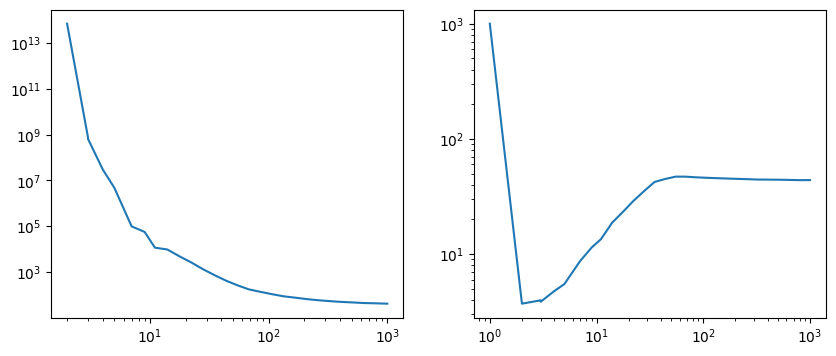

In [21]:
d = 128
ns, steps, distances = run_sample_benchmark(d)
fix, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].loglog(ns, distances)
ax[1].loglog(ns, steps)

KeyboardInterrupt: 

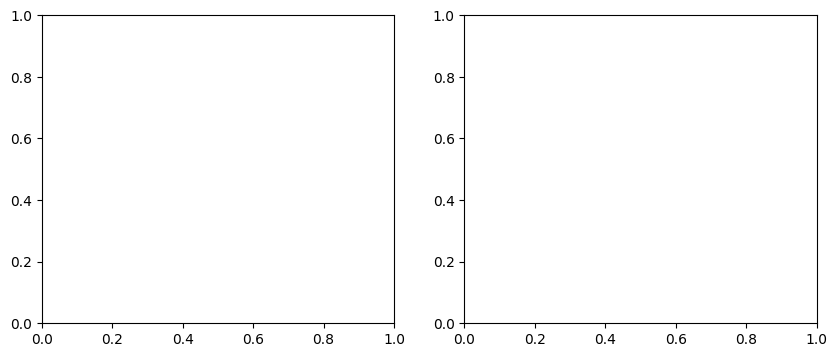

In [22]:
fix, ax = plt.subplots(1, 2, figsize=(10, 4))
ds = 4**np.arange(5)
for d in ds:
    ns, steps, distances = run_sample_benchmark(d)
    ax[0].loglog(ns, distances)
    ax[1].loglog(ns, steps, label=f"{d} Dimensions")
    ax[1].legend()